# 01 — Expected care, Logistic Regression and Random Forest
COM747 · DS&ML CW2

**Research topic:** Multidimensional Care-Intensity Discordance and 30-Day Hospital Readmission in Patients with Diabetes.

Run this notebook after `cleaning/cleaning.ipynb` and `cleaning/validation.ipynb`. Select **Python (DSML CW2)**. Run all cells in order. Two readmission classifiers are trained here; the auxiliary expected-care regression is shared by both notebooks. No test outcomes are evaluated here.

The prediction point is discharge. Expected care is a statistical reference, not medically appropriate care. Diagnosis information may be recorded during the stay, so this is not an admission-time forecast.

## 1. Load the validated data contract and define reusable functions

In [1]:
from pathlib import Path
import hashlib, json, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, confusion_matrix, precision_recall_curve,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

SEED = 42
JOBS = 2  # bounded parallelism; adjust for your machine
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if
    (p/'data/processed/feature_contract.json').is_file()), None)
if root is None:
    raise FileNotFoundError('Run cleaning/cleaning.ipynb and validation.ipynb first.')
DATA = root/'data/processed'
OUT = root/'models'/'outputs'
OUT.mkdir(parents=True, exist_ok=True)
contract = json.loads((DATA/'feature_contract.json').read_text())
report = json.loads((DATA/'validation_report.json').read_text())
if not report['passed']:
    raise ValueError('Data validation did not pass.')
def sha(path):
    with path.open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()
for name, expected in contract['output_sha256'].items():
    if sha(DATA/name) != expected:
        raise ValueError(f'{name} changed; rerun cleaning and validation.')
if sha(root/'data/raw/diabetic_data.csv') != contract['source_sha256']:
    raise ValueError('Raw data changed; rerun cleaning and validation.')
CONTRACT_HASH = sha(DATA/'feature_contract.json')
TARGET = contract['target']
GROUP = contract['group']
CLINICAL = contract['clinical_features']
CARE = contract['observed_care_features']
DISC = contract['planned_discordance_features']
SETS = {'A':contract['feature_set_A'], 'B':contract['feature_set_B'],
        'C':contract['feature_set_C_planned']}
CATS = contract['clinical_categorical']
FORBIDDEN = {TARGET, GROUP, contract['id'], 'split', 'readmitted', *contract['audit_only']}
assert all(not FORBIDDEN.intersection(cols) for cols in SETS.values())

def load(name):
    d = pd.read_csv(DATA/f'{name}.csv', keep_default_na=False, na_values=['?', ''],
                   dtype={GROUP:str, contract['id']:str})
    for col in CATS:
        # Keep coded categories categorical, including admission ID codes.
        if col in ['admission_type_id', 'admission_source_id']:
            d[col] = pd.to_numeric(d[col], errors='raise').map(lambda x: str(int(x)) if pd.notna(x) else np.nan).astype(object)
        else:
            d[col] = d[col].map(lambda x: str(x) if pd.notna(x) else np.nan).astype(object)
    for col in contract['clinical_numeric'] + CARE:
        d[col] = pd.to_numeric(d[col], errors='raise').astype(float)
    assert set(d[TARGET]) == {0,1} and d[GROUP].notna().all()
    return d

def preprocess(cols):
    cat = [c for c in cols if c in CATS]
    num = [c for c in cols if c not in CATS]
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                              ('scale', StandardScaler())]), num),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                                  ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)
    ])

def score(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, list(model.classes_).index(1)]
    return model.decision_function(X)  # SVM margins, not probabilities

def threshold_for_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = np.divide(2*p[:-1]*r[:-1], p[:-1]+r[:-1], out=np.zeros_like(t), where=(p[:-1]+r[:-1])>0)
    return float(t[np.argmax(f)])

def metrics(y, s, threshold):
    pred = (s >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    return dict(AP=average_precision_score(y,s), ROC_AUC=roc_auc_score(y,s),
                precision=precision_score(y,pred,zero_division=0), recall=recall_score(y,pred,zero_division=0),
                F1=f1_score(y,pred,zero_division=0), FNR=fn/(fn+tp),
                TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp), threshold=threshold)

def fit_family(name, candidates, train, val):
    rows, winners, trials = [], {}, []
    for label, cols in SETS.items():
        best = None
        for config, estimator in candidates():
            pipe = Pipeline([('preprocess', preprocess(cols)), ('model', estimator)])
            start = time.perf_counter()
            pipe.fit(train[cols], train[TARGET])
            elapsed = time.perf_counter()-start
            s = score(pipe, val[cols])
            ap = average_precision_score(val[TARGET], s)
            trials.append(dict(model=name, feature_set=label, config=config, AP=ap, fit_seconds=elapsed))
            if best is None or ap > best['AP']:
                best = dict(AP=ap, config=config, pipeline=pipe, scores=s, fit_seconds=elapsed)
        t = threshold_for_f1(val[TARGET], best['scores'])
        rows.append(dict(model=name, feature_set=label, config=best['config'], fit_seconds=best['fit_seconds'],
                         **metrics(val[TARGET], best['scores'], t)))
        winners[(name,label)] = dict(pipeline=best['pipeline'], threshold=t, config=best['config'])
    return rows, winners, trials

print('Project:', root, '| Kernel:', sys.executable)
print('Data validation passed; held-out test is reserved until final evaluation.')

Project: /Users/monishachandrashekar/Desktop/DS&ML-CW2 /Data-science-and-Machine-Learning-Course-work | Kernel: /Users/monishachandrashekar/Desktop/DS&ML-CW2 /.venv/bin/python
Data validation passed; held-out test is reserved until final evaluation.


## 2. Load training and validation only
Use the existing patient-level partitions. No random encounter-level resplitting.

In [2]:
train = load('train')
val = load('validation')
assert set(train[GROUP]).isdisjoint(val[GROUP])
print('Train:', len(train), '| Validation:', len(val))
print('Training positive prevalence:', train[TARGET].mean())

Train: 59604 | Validation: 19871
Training positive prevalence: 0.11388497416280786


## 3. Estimate expected care using patient-grouped out-of-fold predictions
A fixed multi-output Random Forest regressor estimates all four care dimensions from clinical features only. Target scaling inside each fit prevents the largest-scale care count from dominating tree splits. This auxiliary model is not one of the four readmission classifiers. For each training encounter, its expected-care estimate comes from a model that has never seen that patient's encounters. The final benchmark is fitted only on the full training set and applied to validation (and later test).

No readmission labels are used as regression predictors or outcomes; they only balance grouped folds. Fixed regression settings avoid tuning the benchmark on held-out outcomes.

In [3]:
def care_model():
    reg = RandomForestRegressor(n_estimators=80, max_depth=12, min_samples_leaf=20,
                                random_state=SEED, n_jobs=JOBS)
    return Pipeline([('preprocess', preprocess(CLINICAL)),
        ('regressor', TransformedTargetRegressor(regressor=reg, transformer=StandardScaler()))])

folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = np.full((len(train), len(CARE)), np.nan)
seen = np.zeros(len(train), dtype=int)
for i, (fit_idx, hold_idx) in enumerate(folds.split(train, train[TARGET], train[GROUP]), 1):
    assert set(train.iloc[fit_idx][GROUP]).isdisjoint(train.iloc[hold_idx][GROUP])
    m = care_model()
    m.fit(train.iloc[fit_idx][CLINICAL], train.iloc[fit_idx][CARE])
    oof[hold_idx] = m.predict(train.iloc[hold_idx][CLINICAL])
    seen[hold_idx] += 1
    print(f'Expected-care fold {i}/5 complete')
assert (seen == 1).all() and np.isfinite(oof).all()
benchmark = care_model().fit(train[CLINICAL], train[CARE])
val_expected = benchmark.predict(val[CLINICAL])
reg_results = pd.DataFrame([dict(dimension=c, partition=part,
    MAE=mean_absolute_error(d[c], pred[:,j]), RMSE=np.sqrt(mean_squared_error(d[c], pred[:,j])))
    for part,d,pred in [('train_OOF',train,oof),('validation',val,val_expected)]
    for j,c in enumerate(CARE)])
display(reg_results)
reg_results.to_csv(OUT/'expected_care_metrics.csv',index=False)

Expected-care fold 1/5 complete
Expected-care fold 2/5 complete
Expected-care fold 3/5 complete
Expected-care fold 4/5 complete
Expected-care fold 5/5 complete


,dimension,partition,MAE,RMSE
0,time_in_hospital,train_OOF,2.138636,2.765377
1,num_lab_procedures,train_OOF,13.767088,17.873756
2,num_procedures,train_OOF,1.147028,1.491453
3,num_medications,train_OOF,5.450628,7.336980
4,time_in_hospital,validation,2.137645,2.759524
5,num_lab_procedures,validation,13.687944,17.758109
6,num_procedures,validation,1.141009,1.483879
7,num_medications,validation,5.489461,7.328446


## 4. Engineer four signed standardised discordance features
For each dimension, discordance = (observed − expected) / training OOF residual standard deviation. Divide by the training scale without subtracting its mean, preserving zero as exact agreement. Negative means less observed care than the benchmark; positive means more. These are not evidence of under-treatment or over-treatment. Four separate features preserve direction and avoid cancellation. A zero-variance dimension uses scale 1 and is flagged.

,count,mean,std,min,25%,50%,75%,max
discordance_time_in_hospital,59604.0,0.000731,1.000008,-3.091631,-0.702912,-0.232073,0.479531,4.066341
discordance_num_lab_procedures,59604.0,-0.000239,1.000008,-3.207716,-0.529934,0.050280,0.658299,4.373911
discordance_num_procedures,59604.0,-0.000184,1.000008,-3.121616,-0.641952,-0.287366,0.449872,3.894807
discordance_num_medications,59604.0,0.000524,1.000008,-3.175730,-0.658153,-0.135866,0.491027,8.178885


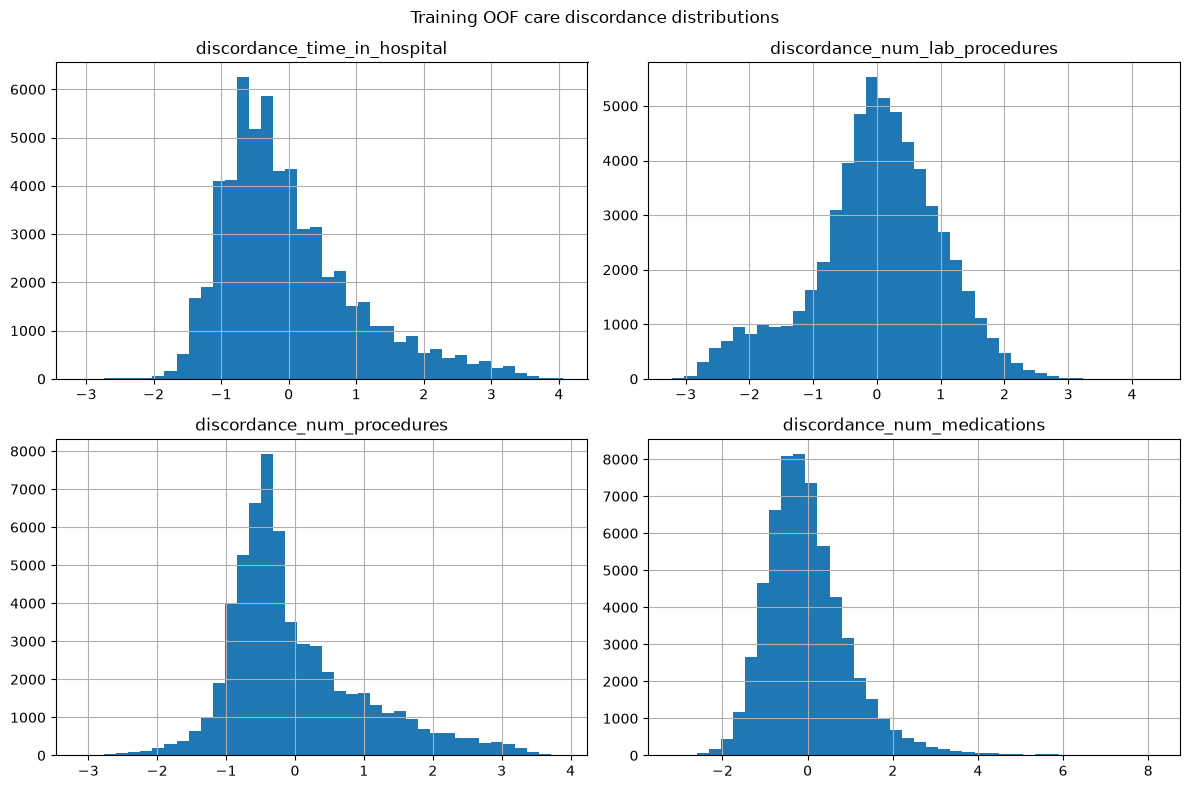

['/Users/monishachandrashekar/Desktop/DS&ML-CW2 /Data-science-and-Machine-Learning-Course-work/models/outputs/discordance_bundle.joblib']

In [4]:
residuals = train[CARE].to_numpy() - oof
scale = residuals.std(axis=0, ddof=0)
if (scale < 1e-12).any():
    print('Warning: constant residual dimension; using scale 1 for it.')
scale = np.where(scale < 1e-12, 1.0, scale)

def add_discordance(d, expected, scale):
    result = d.copy()
    result[DISC] = (d[CARE].to_numpy() - expected)/scale
    assert np.isfinite(result[DISC].to_numpy()).all()
    return result
train = add_discordance(train, oof, scale)
val = add_discordance(val, val_expected, scale)
display(train[DISC].describe().T)
train[DISC].hist(bins=40, figsize=(12,8))
plt.suptitle('Training OOF care discordance distributions')
plt.tight_layout(); plt.show()
# Private local artefact: contains patient identifiers and prepared training/validation data.
joblib.dump(dict(contract_hash=CONTRACT_HASH, benchmark=benchmark, scale=scale,
                 train=train, validation=val), OUT/'discordance_bundle.joblib', compress=3)

## 5. Classifier 1 — Logistic Regression
Compare clinical-only (A), clinical plus actual care (B), and clinical plus actual care plus discordance (C). Tune a small regularisation grid on validation average precision (AP). Class weights address imbalance. Fit all preprocessing on training only. Thresholds maximise validation F1; they are not clinical recommendations.

In [5]:
def logistic_candidates():
    for c in [0.1, 1.0, 10.0]:
        yield f'C={c}', LogisticRegression(C=c, class_weight='balanced', max_iter=1000, random_state=SEED)
lr_rows, lr_models, lr_trials = fit_family('Logistic Regression', logistic_candidates, train, val)
display(pd.DataFrame(lr_rows).round(4))

,model,feature_set,config,fit_seconds,AP,ROC_AUC,precision,recall,F1,FNR,TN,FP,FN,TP,threshold
0,Logistic Regression,A,C=0.1,0.4132,0.2022,0.6412,0.1914,0.4240,0.2637,0.5760,13551,4056,1304,960,0.5280
1,Logistic Regression,B,C=0.1,0.4319,0.2030,0.6460,0.2029,0.3737,0.2630,0.6263,14283,3324,1418,846,0.5503
2,Logistic Regression,C,C=0.1,0.4891,0.2027,0.6461,0.1792,0.5066,0.2648,0.4934,12354,5253,1117,1147,0.5095


## 6. Classifier 2 — Random Forest
Compare three feature sets with the same splits, validation metric, and threshold policy. The forest is a nonlinear classifier, distinct from the auxiliary regression model.

In [6]:
def forest_candidates():
    for depth in [8, 16, None]:
        yield f'max_depth={depth}', RandomForestClassifier(n_estimators=120, max_depth=depth,
            min_samples_leaf=10, class_weight='balanced_subsample', random_state=SEED, n_jobs=JOBS)
rf_rows, rf_models, rf_trials = fit_family('Random Forest', forest_candidates, train, val)
display(pd.DataFrame(rf_rows).round(4))

,model,feature_set,config,fit_seconds,AP,ROC_AUC,precision,recall,F1,FNR,TN,FP,FN,TP,threshold
0,Random Forest,A,max_depth=16,1.6813,0.2064,0.6408,0.2006,0.3936,0.2657,0.6064,14056,3551,1373,891,0.5206
1,Random Forest,B,max_depth=8,1.3471,0.2089,0.6476,0.1871,0.4757,0.2686,0.5243,12929,4678,1187,1077,0.5117
2,Random Forest,C,max_depth=None,3.2134,0.2052,0.6482,0.1929,0.4139,0.2631,0.5861,13686,3921,1327,937,0.4270


## 7. Save the six validation-selected classifiers and results

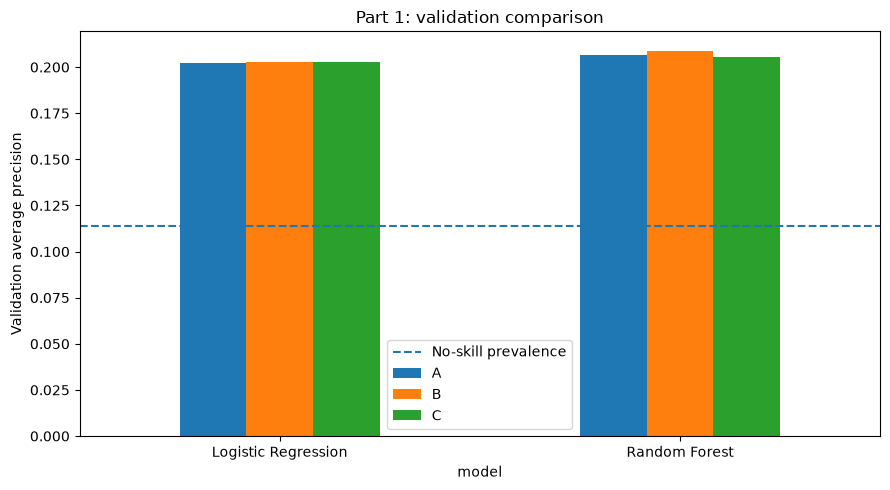

Run 02_svm_xgboost.ipynb next. No final test evaluation yet.


In [7]:
results = pd.DataFrame(lr_rows + rf_rows)
results.to_csv(OUT/'validation_part1.csv',index=False)
pd.DataFrame(lr_trials + rf_trials).to_csv(OUT/'tuning_part1.csv',index=False)
joblib.dump(dict(contract_hash=CONTRACT_HASH, discordance_hash=sha(OUT/'discordance_bundle.joblib'),
    models={**lr_models, **rf_models}), OUT/'classifiers_part1.joblib',compress=3)
results.pivot(index='model',columns='feature_set',values='AP')[['A','B','C']].plot.bar(figsize=(9,5))
plt.axhline(val[TARGET].mean(), linestyle='--', label='No-skill prevalence')
plt.ylabel('Validation average precision'); plt.title('Part 1: validation comparison')
plt.xticks(rotation=0); plt.legend(); plt.tight_layout(); plt.show()
print('Run 02_svm_xgboost.ipynb next. No final test evaluation yet.')

## Interpretation notes
AP is the non-interpolated summary of the precision–recall curve, reported consistently rather than trapezoidal PR-AUC. Validation is used for selection, not final evidence. Derived features do not add independent raw information to Set B; they may improve how models learn from it. Keep outputs containing patient-level data and fitted models local; do not commit them to a public repository.